# The Advection Equation

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display

As a first exercise, we'll solve the 1D linear convection equation with a *square wave* initial condition, defined as follows:

\begin{equation}
u(x,0)=\begin{cases}2 & \text{where } 0.5\leq x \leq 1,\\
1 & \text{everywhere else in } (0, 2)
\end{cases}
\end{equation}

<img style="float: center;" src="figures/Uo_square.png">

Our spatial domain for the numerical solution will only cover the range $x\in (0, 2)$.

## Setup

In [3]:
# setup the domain 

xstart = 0
xend = 2
nx = 50

dt = 0.02

c = 1

dx = (xend-xstart)/(nx-1)
x = np.linspace(xstart,xend,nx)

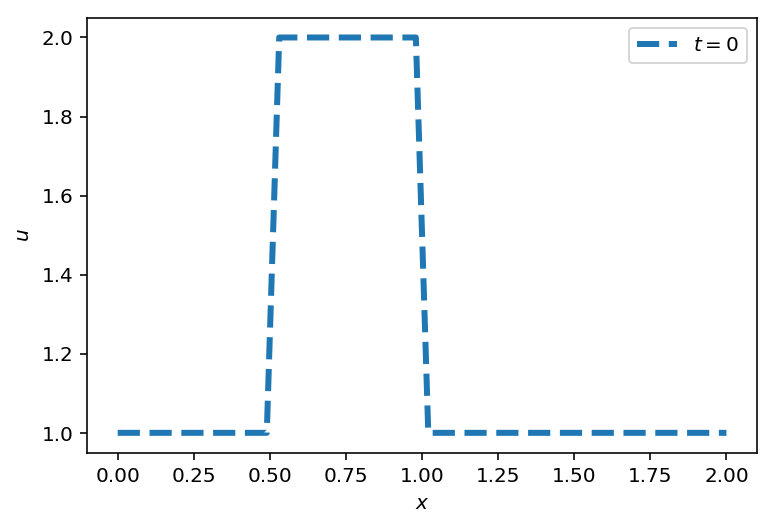

In [4]:
# setup the initial condition

u0 = np.ones(nx)

lbound = np.where(x>=0.5)
ubound = np.where(x<=1)
bounds = np.intersect1d(lbound, ubound)
u0[bounds] = 2

fig, ax = plt.subplots()
ax.plot(x,u0, ls='--', lw=3, label='$t=0$')
ax.set_xlabel('$x$')
ax.set_ylabel('$u$')
plt.legend();

## Use FTBS

In [5]:
# define the initial condition

u = np.zeros(nx)
u = u0.copy()

# run the calculation

nt = 25 # number of iterations

for n in range(1,nt):  
    un = u.copy()
    # interior points
    for i in range(1,nx): 
        u[i] = un[i]-c*dt/dx*(un[i]-un[i-1])
    
time = dt*nt

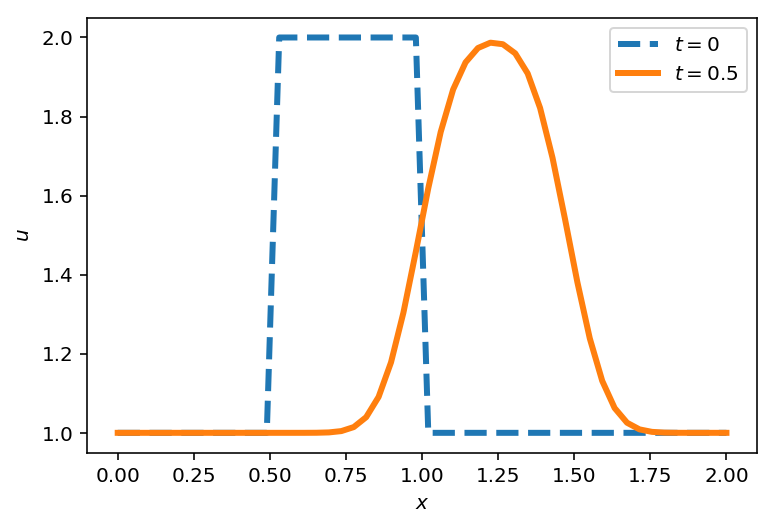

In [6]:
# plot the results

runt=str(np.around(time,decimals=2))

fig, ax = plt.subplots()
ax.plot(x,u0, ls='--', lw=3, label='$t=0$')
ax.plot(x,u, ls='-', lw=3, label='$t=$'+runt)
ax.set_xlabel('$x$')
ax.set_ylabel('$u$')
plt.legend();

Compare to the analytic solution

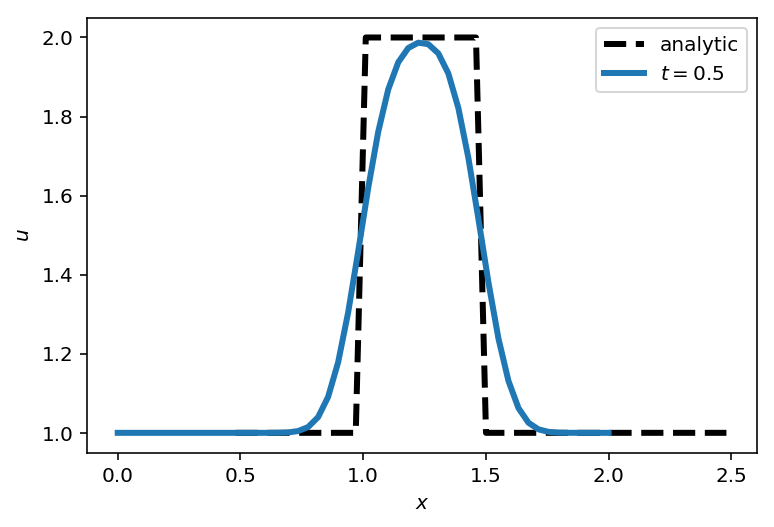

In [7]:
# let's just create a new x axis
xa = np.zeros(nx)
xa = (x+c*(time-dt))

# plot the results

fig, ax = plt.subplots()
ax.plot(xa,u0, ls='--',color='k', lw=3, label='analytic')
ax.plot(x,u, ls='-', lw=3, label='$t=$'+runt)
ax.set_xlabel('$x$')
ax.set_ylabel('$u$')
plt.legend();

Let's put a periodic bc in and see what happens if we run it a long time

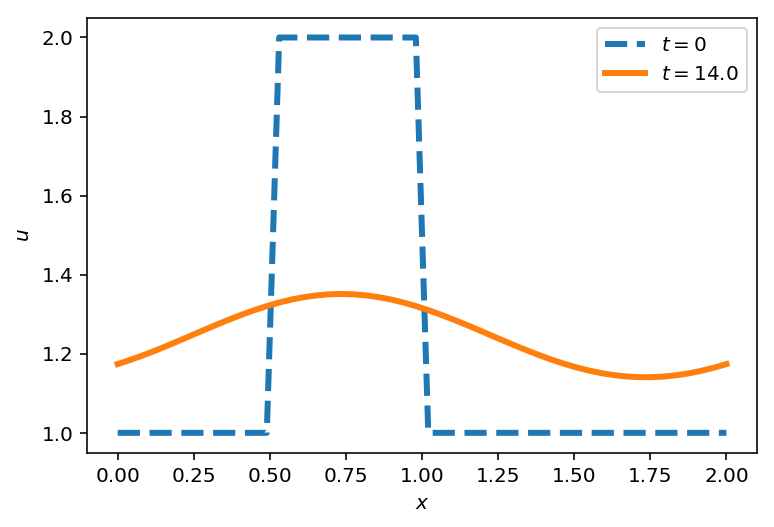

In [8]:
# run the calculation

nt = 700 # number of iterations
u = u0.copy()

for n in range(1,nt):  
    un = u.copy()
    # interior points
    for i in range(1,nx): 
        u[i] = un[i]-c*dt/dx*(un[i]-un[i-1])
    u[0]=u[-1]

    
time = dt*nt
runt=str(np.around(time, decimals=3))

# plot the results

fig, ax = plt.subplots()
ax.plot(x,u0, ls='--', lw=3, label='$t=0$')
ax.plot(x,u, ls='-', lw=3, label='$t=$'+runt)
ax.set_xlabel('$x$')
ax.set_ylabel('$u$')
plt.legend();

## Using FTCS

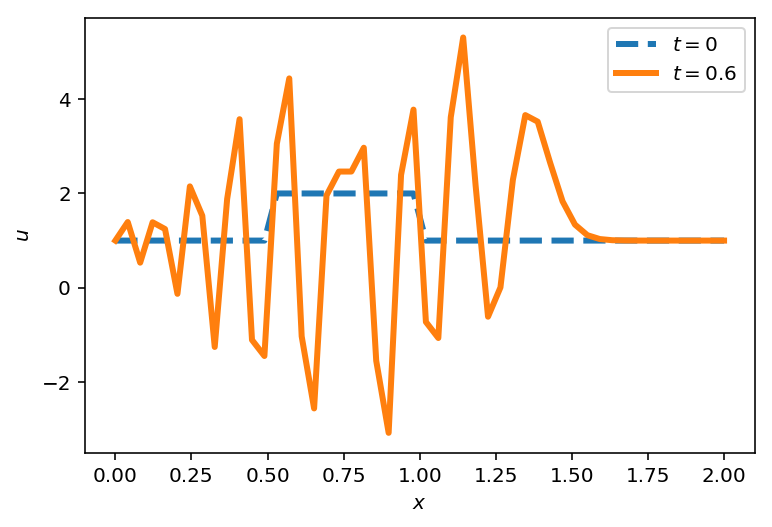

In [9]:
# define the initial condition

dt =0.02
nt = 30

u = np.zeros(nx)
u = u0.copy()

# run the calculation

for n in range(1,nt):  
    un = u.copy()
    # interior points
    for i in range(1,nx-1): 
        u[i] = un[i]-c*dt/(2*dx)*(un[i+1]-un[i-1])


time = dt*nt
runt=str(np.around(time, decimals=3))
# plot the results

fig, ax = plt.subplots()
ax.plot(x,u0, ls='--', lw=3, label='$t=0$')
ax.plot(x,u, ls='-', lw=3, label='$t=$'+runt)
ax.set_xlabel('$x$')
ax.set_ylabel('$u$')
plt.legend();

## Stability of FTBS?

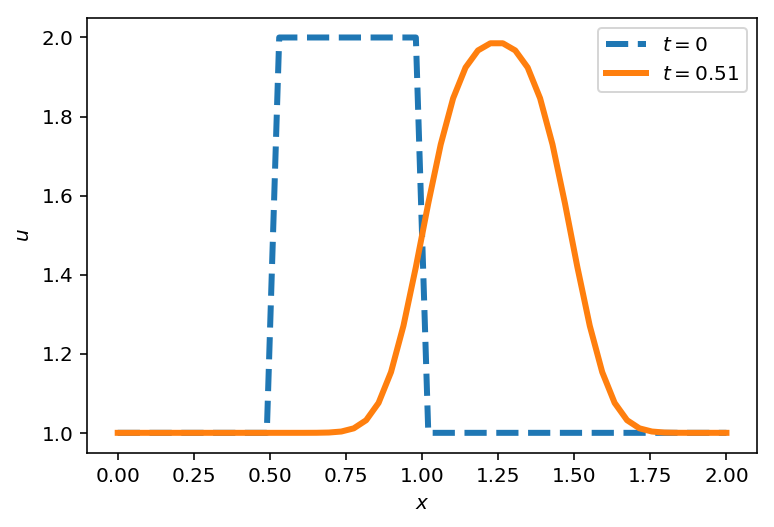

In [10]:
# setup the domain 

# stable for dt < dx/c

c = 1
dt = dx/c/2 #0.02


nt = 25 # number of iterations
u = u0.copy()

for n in range(1,nt):  
    un = u.copy()
    # interior points
    for i in range(1,nx): 
        u[i] = un[i]-c*dt/dx*(un[i]-un[i-1])
    u[0]=u[-1]

    
time = dt*nt
runt=str(np.around(time, decimals=3))

# plot the results

fig, ax = plt.subplots()
ax.plot(x,u0, ls='--', lw=3, label='$t=0$')
ax.plot(x,u, ls='-', lw=3, label='$t=$'+runt)
ax.set_xlabel('$x$')
ax.set_ylabel('$u$')
plt.legend();

In [11]:
dx

0.04081632653061224

In [12]:
dx/c/2

0.02040816326530612

## Other methods?

### Lax

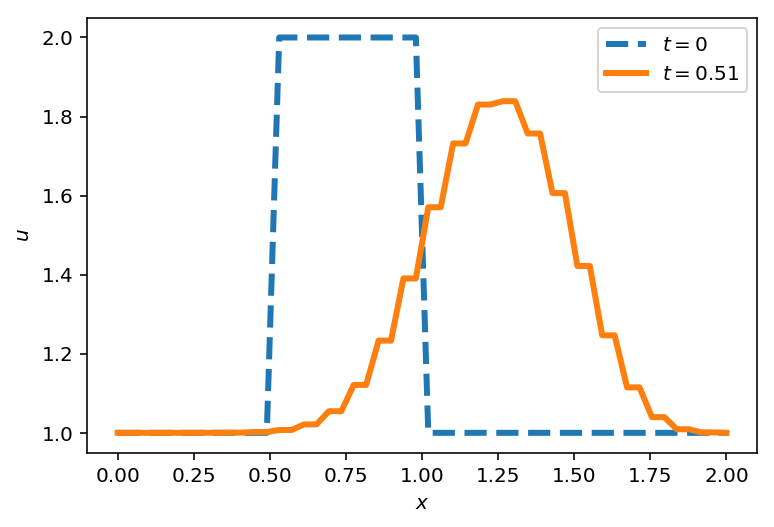

In [16]:
xstart = 0
xend = 2
nx = 50

c = 1

dx = (xend-xstart)/(nx-1)
x = np.linspace(xstart,xend,nx)

dt = dx/c/2
nt = 25

u0 = np.ones(nx)

lbound = np.where(x>=0.5)
ubound = np.where(x<=1)
bounds = np.intersect1d(lbound, ubound)
u0[bounds] = 2

u = np.zeros(nx)
u = u0.copy()

# run the calculation

for n in range(1,nt):  
    un = u.copy()
    # interior points
    for i in range(1,nx-1): 
        u[i] = 0.5*(un[i+1]+un[i-1])-c*(dt/(2*dx))*(un[i+1]-un[i-1])
    u[-1]=un[-1]-c*(dt/dx)*(un[-1]-un[-2])
    u[0]=u[-1]


time = dt*nt
runt=str(np.around(time, decimals=3))
# plot the results

fig, ax = plt.subplots()
ax.plot(x,u0, ls='--', lw=3, label='$t=0$')
ax.plot(x,u, ls='-', lw=3, label='$t=$'+runt)
ax.set_xlabel('$x$')
ax.set_ylabel('$u$')
plt.legend();